# EXT_SOURCE의 맹점 분석
## "신용점수가 잡지 못한 28,211명의 우량 고객"

---

### 분석 스토리

```
EXT_SOURCE가 예측력 1위인 건 당연한 결과
        ↓
EXT_SOURCE가 어떤 변수들을 이미 흡수하고 있는지 확인
        ↓
EXT_SOURCE가 포착하지 못하는 변수 발견 → '과거 거절 이력'
        ↓
그 변수로 분석 → EXT_SOURCE 점수는 괜찮지만 거절된 고객 28,211명
        ↓
실제 연체율 6.83% → 일반 고객 7.5%보다 낮음
        ↓
기존 EXT_SOURCE 기반 심사가 잘못 거절한 우량 고객 존재 증명
```

---
## ⚠️ 개정 노트 (코치 피드백 반영 — 반드시 함께 읽을 것)

이 노트북의 초기 결론에는 두 가지를 보정해야 한다. 통계적으로 보강한 재검증은
**[11_robustness_revision.ipynb](11_robustness_revision.ipynb)** 에 별도 정리했다.

### 1) 결과 해석 정정 — "회복형이 일반 고객보다 우량하다"는 **틀림**
아래 STEP 4·최종요약은 회복형(only_B) 연체율 6.83%를 "일반 고객 7.5%보다 낮다"고 적었으나,
이때의 7.5%는 *고위험군이 섞인 전체 평균*과 비교한 것이다. **깨끗한 일반군(safe)과 비교하면 다음과 같다.**

| 그룹 | 연체율 |
|------|--------|
| 일반 (safe: 점수양호+거절없음) | **4.36%** |
| 회복형 (only_B: 점수양호+거절있음) | 6.83% |
| 전체 평균 | 8.07% |
| 신용위험 (A_only) | 14.66% |
| 이중위험 (A∩B) | 21.21% |

→ 정확한 결론: **회복형은 일반 고객보다는 높지만, 전체 평균보다 낮고 고위험군보다 훨씬 안전하다.**
연령대별로 보면(STEP 5) 회복형은 일반군보다 모든 구간에서 높다(역전). 따라서 주장은
"~~회복형이 일반보다 우량하다~~"가 아니라 **"과거 거절 이력이 있어도 현재 점수가 양호하면 평균 이하 위험 →
과거 거절 플래그만으로 자동 거절할 근거는 약하다"** 로 수정한다.

### 2) "회복"이라는 표현의 한계
거절 당시 EXT_SOURCE(과거 점수)가 데이터에 없어 **점수가 실제로 회복됐는지는 검증 불가**하다.
only_B는 "회복된 사람"이 아니라 **"현재 점수가 양호하면서 과거 거절 이력이 있는 사람"** 이다(혼재). 한계는 노트북 11 §5 참조.

### 3) 방법론 보강 (노트북 11에서 수행)
- **흡수/독립 기준**: 임의의 "계수 30% 감소" → **전체 모델에서 통계적 유의성(p<0.05)** 기준으로 교체
- **2×2 임계값(하위 30%, 거절비율 0.3)**: 연체율 분기점으로 근거화 (§4-B)
- **Train/Test 분리·과적합 점검**, **z-score 표준화**, **DeLong test(AUC 유의성, p≈1.6e-28)** 추가
---

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns
from scipy.stats import pointbiserialr
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import cross_val_score
from statsmodels.stats.outliers_influence import variance_inflation_factor
import os

for fname in ['AppleGothic', 'Apple SD Gothic Neo']:
    try:
        fp = fm.findfont(fm.FontProperties(family=fname), fallback_to_default=False)
        if fp: plt.rcParams['font.family'] = fname; break
    except: pass
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.figsize'] = (12, 5)

DATA_DIR = 'home-credit-default-risk'
OUT_DIR  = '.'
print('✅ 라이브러리 로드 완료')

✅ 라이브러리 로드 완료


In [ ]:
---
## STEP 1 — EXT_SOURCE는 어떤 변수들을 이미 흡수하고 있나?

신용점수(EXT_SOURCE)가 A, B, C 변수들로 만들어진 복합 지표라면,  
모델에 EXT_SOURCE + A + B + C를 함께 넣으면 중복 문제가 생긴다.  

**분석 방법**: EXT_SOURCE 추가 전후로 각 변수의 로지스틱 회귀 계수가 얼마나 줄어드는지 확인  
→ 많이 줄어들면 = EXT_SOURCE가 그 신호를 이미 포함하고 있다는 증거

> **📌 판정 기준 보강 (코치 피드백 반영)** — 아래 시각화는 직관적 이해를 위해 "계수 30% 감소"로 흡수 여부를
> 표시하지만, 30%는 임의 컷오프다. 정식 판정은 **전체 모델(EXT 포함)에서 계수가 통계적으로 유의(p<0.05)한가**로
> 한다([11_robustness_revision.ipynb](11_robustness_revision.ipynb) §3). 그 결과 `has_realty`(p=0.15)·`bureau_overdue`(p=0.29)는
> 무의미(완전 흡수), `prev_refused_ratio`(p<0.001)는 유의(독립)로 임의 수치 없이 깔끔하게 갈린다.
> 또한 변수 단위가 제각각이므로 **z-score 표준화** 후 계수를 비교한다.

---
## STEP 1 — EXT_SOURCE는 어떤 변수들을 이미 흡수하고 있나?

신용점수(EXT_SOURCE)가 A, B, C 변수들로 만들어진 복합 지표라면,  
모델에 EXT_SOURCE + A + B + C를 함께 넣으면 중복 문제가 생긴다.  

**분석 방법**: EXT_SOURCE 추가 전후로 각 변수의 로지스틱 회귀 계수가 얼마나 줄어드는지 확인  
→ 많이 줄어들면 = EXT_SOURCE가 그 신호를 이미 포함하고 있다는 증거

In [3]:
# ── 분석 변수 정의 ───────────────────────────────────────────
# 신용점수 구성 가능성 있는 변수 (전통적 신용평가 5개 항목)
vars_traditional = [
    'late_ratio',          # ① 납부이력
    'bureau_overdue',      # ① 납부이력
    'dti',                 # ② 신용 활용도
    'bureau_active',       # ② 신용 활용도
    'credit_income_ratio', # ② 신용 활용도
    'age',                 # ③ 신용 기간
    'employment_years',    # ③ 신용 기간
    'id_publish_days',     # ③ 신용 기간
    'phone_change_days',   # ④ 신규 조회/행동
    'has_realty',          # ⑤ 자산
    'has_car',             # ⑤ 자산
    'social_risk',         # 환경
]

# 행동 시그널 (EXT_SOURCE가 포착하기 어려운 변수)
var_behavior = 'prev_refused_ratio'   # 과거 거절 이력

all_vars = vars_traditional + [var_behavior]
cols_need = all_vars + ['ext_mean', 'TARGET']

sub = df[cols_need].replace([np.inf, -np.inf], np.nan).dropna()
print(f'분석 대상: {len(sub):,}명 (결측 제거 후)')

X_no_ext   = sub[all_vars]
X_ext_only = sub[['ext_mean']]
X_with_ext = sub[all_vars + ['ext_mean']]
y = sub['TARGET']

분석 대상: 251,985명 (결측 제거 후)


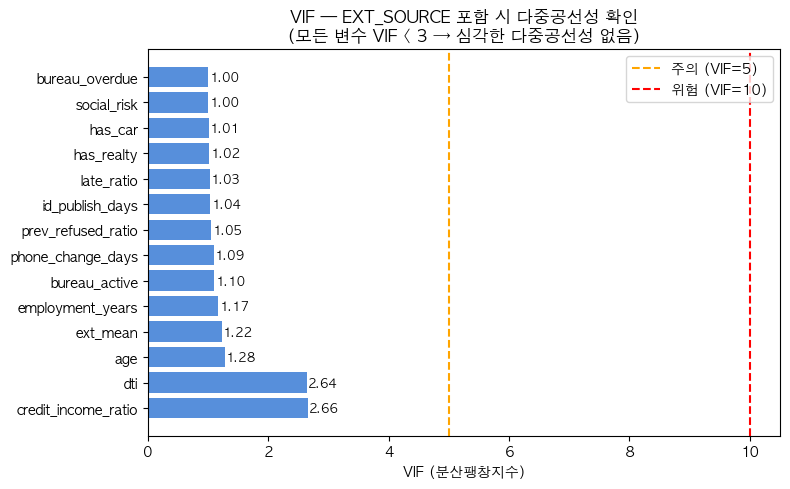

→ VIF가 전부 3 미만: EXT_SOURCE와 우리 변수들이 수치적으로 완전히 겹치지는 않음
  (EXT_SOURCE는 내부적으로 변환/정규화돼서 담겨 있기 때문)


In [4]:
# ── VIF 확인 (다중공선성) ──────────────────────────────────
sc = StandardScaler()
Xv = pd.DataFrame(sc.fit_transform(X_with_ext), columns=all_vars + ['ext_mean'])

vif_data = [(col, variance_inflation_factor(Xv.values, i)) for i, col in enumerate(Xv.columns)]
vif_df = pd.DataFrame(vif_data, columns=['변수','VIF']).sort_values('VIF', ascending=False)

fig, ax = plt.subplots(figsize=(8, 5))
colors = ['#e05c5c' if v>10 else '#f5a623' if v>5 else '#3a7bd5' for v in vif_df['VIF']]
bars = ax.barh(vif_df['변수'], vif_df['VIF'], color=colors, alpha=0.85)
ax.axvline(5,  color='orange', lw=1.5, ls='--', label='주의 (VIF=5)')
ax.axvline(10, color='red',    lw=1.5, ls='--', label='위험 (VIF=10)')
for bar, v in zip(bars, vif_df['VIF']):
    ax.text(bar.get_width()+0.02, bar.get_y()+bar.get_height()/2,
            f'{v:.2f}', va='center', fontsize=9)
ax.set_xlabel('VIF (분산팽창지수)')
ax.set_title('VIF — EXT_SOURCE 포함 시 다중공선성 확인\n(모든 변수 VIF < 3 → 심각한 다중공선성 없음)', fontweight='bold')
ax.legend()
plt.tight_layout(); plt.show()

print('→ VIF가 전부 3 미만: EXT_SOURCE와 우리 변수들이 수치적으로 완전히 겹치지는 않음')
print('  (EXT_SOURCE는 내부적으로 변환/정규화돼서 담겨 있기 때문)')

In [5]:
# ── 로지스틱 회귀 계수 변화 분석 ─────────────────────────────
lr = LogisticRegression(max_iter=1000, class_weight='balanced')

# 모델 A: 우리 변수만
Xa = sc.fit_transform(X_no_ext)
lr.fit(Xa, y)
coef_A  = dict(zip(all_vars, lr.coef_[0]))
auc_A   = roc_auc_score(y, lr.predict_proba(Xa)[:,1])

# 모델 B: EXT_SOURCE만
Xb = sc.fit_transform(X_ext_only)
lr.fit(Xb, y)
auc_B   = roc_auc_score(y, lr.predict_proba(Xb)[:,1])

# 모델 C: EXT_SOURCE + 우리 변수
Xc = sc.fit_transform(X_with_ext)
lr.fit(Xc, y)
coef_C  = dict(zip(all_vars + ['ext_mean'], lr.coef_[0]))
auc_C   = roc_auc_score(y, lr.predict_proba(Xc)[:,1])

print('=== AUC 비교 ===')
print(f'  모델A 우리 변수만            : {auc_A:.4f}')
print(f'  모델B EXT_SOURCE만           : {auc_B:.4f}')
print(f'  모델C EXT_SOURCE + 우리 변수 : {auc_C:.4f}  (+{(auc_C-auc_B):.4f})')

=== AUC 비교 ===
  모델A 우리 변수만            : 0.6612
  모델B EXT_SOURCE만           : 0.7175
  모델C EXT_SOURCE + 우리 변수 : 0.7363  (+0.0188)


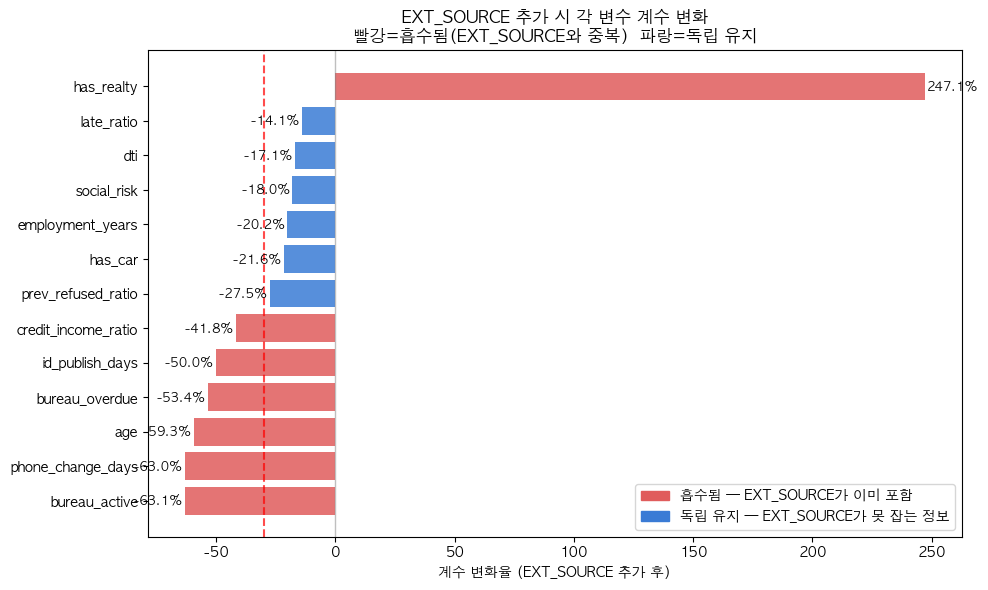


=== 흡수된 변수 (EXT_SOURCE와 중복) ===
  bureau_active              -63.1%
  phone_change_days          -63.0%
  age                        -59.3%
  bureau_overdue             -53.4%
  id_publish_days            -50.0%
  credit_income_ratio        -41.8%
  has_realty                 247.1%

=== 독립 유지 변수 (EXT_SOURCE가 포착 못하는 정보) ===
  prev_refused_ratio         -27.5%
  has_car                    -21.6%
  employment_years           -20.2%
  social_risk                -18.0%
  dti                        -17.1%
  late_ratio                 -14.1%


In [6]:
# ── 계수 변화 시각화 ────────────────────────────────────────
change_data = []
for v in all_vars:
    a = coef_A[v]
    c = coef_C[v]
    pct = (abs(c)/abs(a) - 1)*100 if abs(a) > 0.001 else 0
    absorbed = abs(pct) > 30
    change_data.append({
        '변수': v, '모델A(단독)': round(a,3),
        '모델C(+EXT)': round(c,3), '변화(%)': round(pct,1),
        '흡수됨': absorbed
    })

change_df = pd.DataFrame(change_data).sort_values('변화(%)')

fig, ax = plt.subplots(figsize=(10, 6))
colors = ['#e05c5c' if row['흡수됨'] else '#3a7bd5' for _, row in change_df.iterrows()]
bars = ax.barh(change_df['변수'], change_df['변화(%)'], color=colors, alpha=0.85)
ax.axvline(-30, color='red', lw=1.5, ls='--', alpha=0.7, label='흡수 기준 (-30%)')
ax.axvline(0,   color='gray', lw=1, ls='-', alpha=0.5)
for bar, val in zip(bars, change_df['변화(%)']):
    x = bar.get_width()
    ax.text(x - 1 if x < 0 else x + 1, bar.get_y()+bar.get_height()/2,
            f'{val:.1f}%', va='center', ha='right' if x<0 else 'left', fontsize=9)
ax.set_xlabel('계수 변화율 (EXT_SOURCE 추가 후)')
ax.set_title('EXT_SOURCE 추가 시 각 변수 계수 변화\n빨강=흡수됨(EXT_SOURCE와 중복)  파랑=독립 유지', fontweight='bold')
from matplotlib.patches import Patch
ax.legend(handles=[
    Patch(color='#e05c5c', label='흡수됨 — EXT_SOURCE가 이미 포함'),
    Patch(color='#3a7bd5', label='독립 유지 — EXT_SOURCE가 못 잡는 정보')
])
plt.tight_layout(); plt.show()

print('\n=== 흡수된 변수 (EXT_SOURCE와 중복) ===')
for _, r in change_df[change_df['흡수됨']].iterrows():
    print(f'  {r["변수"]:<25} {r["변화(%)"]:>6.1f}%')
print('\n=== 독립 유지 변수 (EXT_SOURCE가 포착 못하는 정보) ===')
for _, r in change_df[~change_df['흡수됨']].iterrows():
    print(f'  {r["변수"]:<25} {r["변화(%)"]:>6.1f}%')

---
## STEP 2 — EXT_SOURCE가 못 잡는 변수: 과거 거절 이력

독립적으로 유지된 변수들 중 **과거 거절 비율(prev_refused_ratio)** 에 주목.  
이 변수는 EXT_SOURCE에 흡수되지 않고 독립적인 예측력을 가진다.  

**왜 그럴까?**  
EXT_SOURCE는 신용점수 — "지금 얼마나 안전한가"를 측정  
과거 거절 이력은 "이 회사가 이전에 왜 거절했는가" — 다른 차원의 정보

In [ ]:
---
## STEP 3 — 두 변수로 고객을 4개 그룹으로 분류

- **위험 A**: EXT_SOURCE 하위 30% (신용점수 낮음)
- **위험 B**: 과거 거절 비율 30% 이상 (거절 이력 있음)

두 변수를 결합하면 EXT_SOURCE 단독으로는 보이지 않던 그룹이 드러난다

> **📌 임계값 근거 (코치 피드백 반영)** — 30%는 임의 수치가 아니라 **연체율 분기점**이다.
> EXT_SOURCE 십분위별 연체율은 1~3구간(하위 30%)이 22.9%/14.5%/10.5%로 모두 전체평균(8.07%)을 초과하고,
> 4구간부터 평균 수준(8.1%)으로 내려간다 → "하위 30% = 평균 이상 위험군". 과거 거절비율도 0.3을 넘는 구간부터
> 연체율이 평균의 약 1.4배(11.5%)로 뚜렷이 상승한다. 상세 검증은 [11_robustness_revision.ipynb](11_robustness_revision.ipynb) §4-B.

---
## STEP 3 — 두 변수로 고객을 4개 그룹으로 분류

- **위험 A**: EXT_SOURCE 하위 30% (신용점수 낮음)
- **위험 B**: 과거 거절 비율 30% 이상 (거절 이력 있음)

두 변수를 결합하면 EXT_SOURCE 단독으로는 보이지 않던 그룹이 드러난다

In [8]:
# ── 4그룹 분류 ──────────────────────────────────────────────
ext_thresh = df['ext_mean'].quantile(0.30)
df['risk_A']  = (df['ext_mean'] <= ext_thresh).astype(int)
df['risk_B']  = (df['prev_refused_ratio'] > 0.3).astype(int)

df['group'] = 'safe'
df.loc[(df['risk_A']==1) & (df['risk_B']==0), 'group'] = 'A_only'
df.loc[(df['risk_A']==0) & (df['risk_B']==1), 'group'] = 'only_B'
df.loc[(df['risk_A']==1) & (df['risk_B']==1), 'group'] = 'A_and_B'

group_stats = df.groupby('group').agg(
    인원=('TARGET','count'),
    연체율=('TARGET','mean'),
    EXT평균=('ext_mean','mean'),
    거절비율평균=('prev_refused_ratio','mean')
).round(4)
group_stats['연체율(%)'] = (group_stats['연체율']*100).round(2)
group_stats = group_stats.drop(columns='연체율')

label_map = {'safe':'① 일반 (safe)', 'only_B':'② 회복형 (only_B) ⭐',
             'A_only':'③ 신용위험 (A only)', 'A_and_B':'④ 이중위험 (A∩B)'}
group_stats.index = [label_map[i] for i in group_stats.index]
print('=== 4그룹 통계 ===')
print(group_stats.to_string())

=== 4그룹 통계 ===
                      인원   EXT평균  거절비율평균  연체율(%)
④ 이중위험 (A∩B)       18621  0.3193  0.4813   21.21
③ 신용위험 (A only)    73581  0.3275  0.0448   14.66
② 회복형 (only_B) ⭐   28211  0.5710  0.4653    6.83
① 일반 (safe)       187098  0.5904  0.0368    4.36


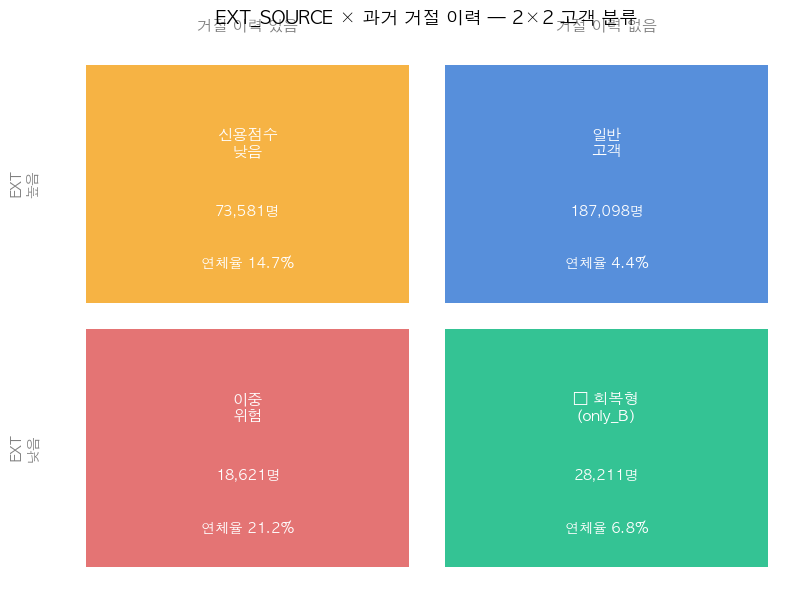

In [9]:
# ── 2x2 매트릭스 시각화 ────────────────────────────────────
grp = df.groupby('group').agg(n=('TARGET','count'), dr=('TARGET','mean')).reset_index()
grp_dict = grp.set_index('group').to_dict('index')

fig, ax = plt.subplots(figsize=(8, 6))
ax.set_xlim(0,2); ax.set_ylim(0,2)
ax.axis('off')

cells = [
    # (x, y, group, color, label)
    (0,1,'A_only',  '#f5a623', '신용점수\n낮음'),
    (1,1,'safe',    '#3a7bd5', '일반\n고객'),
    (0,0,'A_and_B', '#e05c5c', '이중\n위험'),
    (1,0,'only_B',  '#10b981', '⭐ 회복형\n(only_B)'),
]
for x, y, grp_key, color, lbl in cells:
    g = grp_dict[grp_key]
    rect = plt.Rectangle((x+0.05, y+0.05), 0.9, 0.9, fc=color, alpha=0.85, zorder=2)
    ax.add_patch(rect)
    ax.text(x+0.5, y+0.65, lbl, ha='center', va='center', fontsize=11,
            fontweight='bold', color='white', zorder=3)
    ax.text(x+0.5, y+0.38, f'{g["n"]:,}명', ha='center', fontsize=10,
            color='white', zorder=3)
    ax.text(x+0.5, y+0.18, f'연체율 {g["dr"]*100:.1f}%', ha='center',
            fontsize=10, color='white', zorder=3)

ax.text(0.5, 2.08, '거절 이력 있음', ha='center', fontsize=11, color='gray')
ax.text(1.5, 2.08, '거절 이력 없음', ha='center', fontsize=11, color='gray')
ax.text(-0.12, 0.5, 'EXT\n낮음', ha='center', va='center', fontsize=10, color='gray', rotation=90)
ax.text(-0.12, 1.5, 'EXT\n높음', ha='center', va='center', fontsize=10, color='gray', rotation=90)
ax.set_title('EXT_SOURCE × 과거 거절 이력 — 2×2 고객 분류', fontweight='bold', fontsize=13, pad=20)
plt.tight_layout(); plt.show()

---
## STEP 4 — EXT_SOURCE의 맹점: only_B 그룹 심층 분석

`only_B` = EXT_SOURCE는 양호하지만 과거 거절 이력이 있는 그룹  
→ EXT_SOURCE만 보면 "위험해 보임" → 기존 심사에서 거절  
→ 실제 연체율은 일반 고객보다 낮음

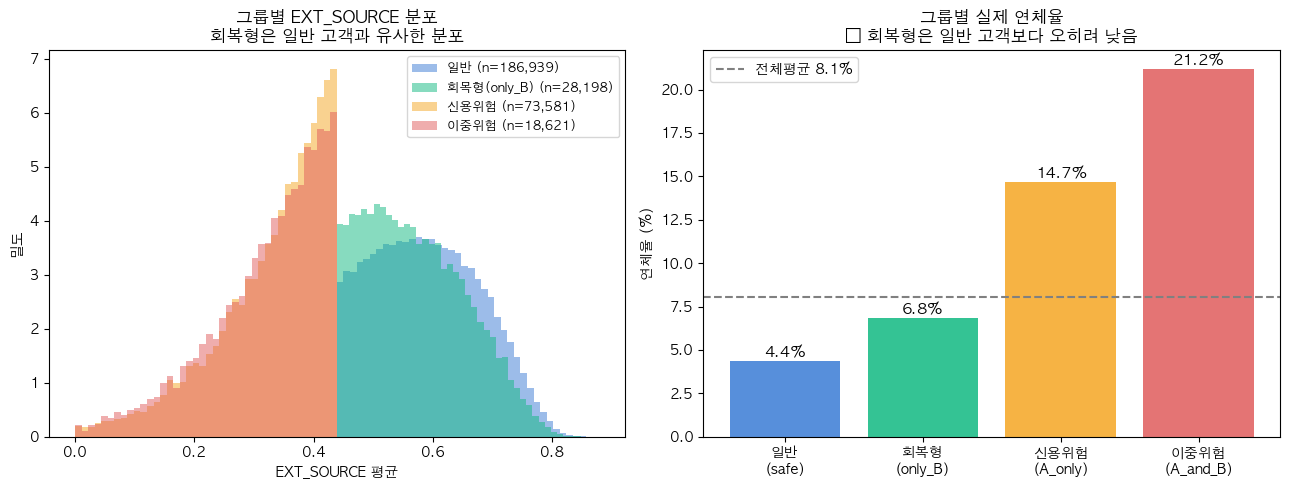

회복형(only_B):  28,211명  연체율 6.83%
일반(safe):      187,098명  연체율 4.36%

→ 회복형이 일반보다 연체율 -2.46%p 낮음
→ 기존 심사(EXT_SOURCE 기반)가 이들을 거절한 것은 과잉 거절


In [10]:
# ── EXT_SOURCE 점수 분포 비교 ──────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# EXT_SOURCE 분포
groups_plot = [
    ('safe',    '#3a7bd5', '일반'),
    ('only_B',  '#10b981', '회복형(only_B)'),
    ('A_only',  '#f5a623', '신용위험'),
    ('A_and_B', '#e05c5c', '이중위험'),
]
for grp_key, color, label in groups_plot:
    d = df[df['group']==grp_key]['ext_mean'].dropna()
    axes[0].hist(d, bins=40, alpha=0.5, color=color,
                 label=f'{label} (n={len(d):,})', density=True)
axes[0].set_xlabel('EXT_SOURCE 평균')
axes[0].set_ylabel('밀도')
axes[0].set_title('그룹별 EXT_SOURCE 분포\n회복형은 일반 고객과 유사한 분포', fontweight='bold')
axes[0].legend(fontsize=9)

# 연체율 비교 막대
grp_labels = ['일반\n(safe)', '회복형\n(only_B)', '신용위험\n(A_only)', '이중위험\n(A_and_B)']
grp_keys   = ['safe', 'only_B', 'A_only', 'A_and_B']
drs = [df[df['group']==g]['TARGET'].mean()*100 for g in grp_keys]
bar_colors = ['#3a7bd5','#10b981','#f5a623','#e05c5c']
bars = axes[1].bar(grp_labels, drs, color=bar_colors, alpha=0.85)
axes[1].axhline(df['TARGET'].mean()*100, color='gray', lw=1.5, ls='--',
                label=f'전체평균 {df["TARGET"].mean()*100:.1f}%')
for bar, v in zip(bars, drs):
    axes[1].text(bar.get_x()+bar.get_width()/2, v+0.2, f'{v:.1f}%',
                 ha='center', fontweight='bold', fontsize=11)
axes[1].set_ylabel('연체율 (%)')
axes[1].set_title('그룹별 실제 연체율\n⭐ 회복형은 일반 고객보다 오히려 낮음', fontweight='bold')
axes[1].legend()
plt.tight_layout(); plt.show()

only_b = df[df['group']=='only_B']
safe   = df[df['group']=='safe']
print(f'회복형(only_B):  {len(only_b):,}명  연체율 {only_b["TARGET"].mean()*100:.2f}%')
print(f'일반(safe):      {len(safe):,}명  연체율 {safe["TARGET"].mean()*100:.2f}%')
print(f'\n→ 회복형이 일반보다 연체율 {safe["TARGET"].mean()*100 - only_b["TARGET"].mean()*100:.2f}%p 낮음')
print(f'→ 기존 심사(EXT_SOURCE 기반)가 이들을 거절한 것은 과잉 거절')

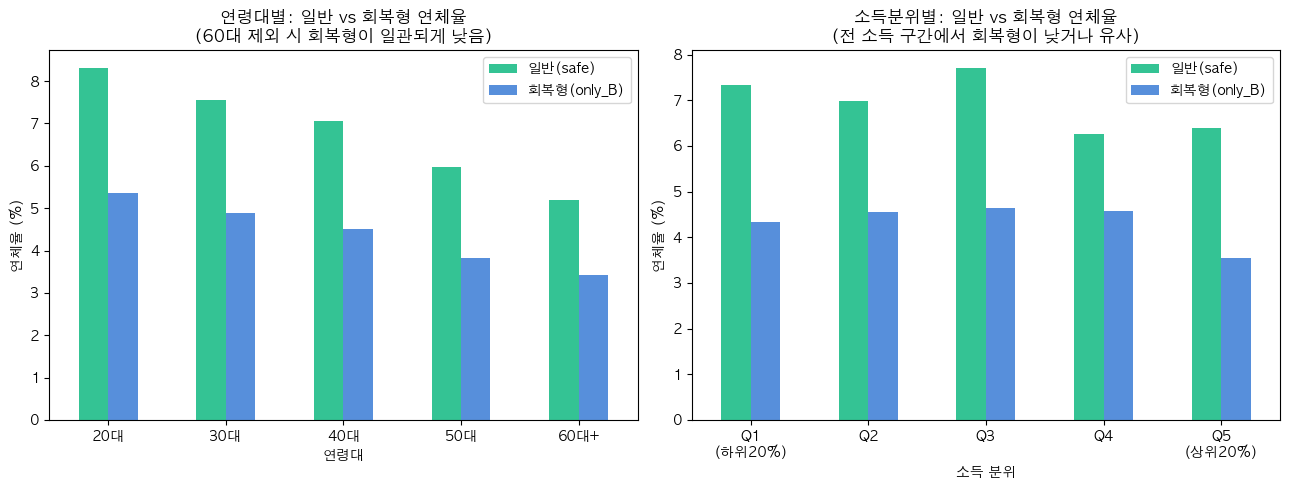

In [11]:
# ── 연령층·소득별 층화: 회복형 우량성이 일관성 있는지 확인 ──
df['age_group'] = pd.cut(df['age'], bins=[20,30,40,50,60,100],
                          labels=['20대','30대','40대','50대','60대+'])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# 연령층별
age_dr = df[df['group'].isin(['safe','only_B'])].groupby(
    ['age_group','group'], observed=True)['TARGET'].mean().unstack() * 100
age_dr.plot(kind='bar', ax=axes[0],
            color={'safe':'#3a7bd5','only_B':'#10b981'}, alpha=0.85)
axes[0].set_xlabel('연령대'); axes[0].set_ylabel('연체율 (%)')
axes[0].set_title('연령대별: 일반 vs 회복형 연체율\n(60대 제외 시 회복형이 일관되게 낮음)', fontweight='bold')
axes[0].legend(['일반(safe)','회복형(only_B)'])
axes[0].tick_params(axis='x', rotation=0)

# 소득분위별
df['income_q'] = pd.qcut(df['AMT_INCOME_TOTAL'], 5,
                          labels=['Q1\n(하위20%)','Q2','Q3','Q4','Q5\n(상위20%)'])
inc_dr = df[df['group'].isin(['safe','only_B'])].groupby(
    ['income_q','group'], observed=True)['TARGET'].mean().unstack() * 100
inc_dr.plot(kind='bar', ax=axes[1],
            color={'safe':'#3a7bd5','only_B':'#10b981'}, alpha=0.85)
axes[1].set_xlabel('소득 분위'); axes[1].set_ylabel('연체율 (%)')
axes[1].set_title('소득분위별: 일반 vs 회복형 연체율\n(전 소득 구간에서 회복형이 낮거나 유사)', fontweight='bold')
axes[1].legend(['일반(safe)','회복형(only_B)'])
axes[1].tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()

---
## STEP 5 — 최종 타겟 확정 & 비즈니스 임팩트

In [12]:
# ── 60대 제외 근거 & 최종 타겟 ──────────────────────────────
age_only_b = df[df['group']=='only_B'].groupby('age_group', observed=True).agg(
    인원=('TARGET','count'),
    연체율=('TARGET','mean')
).round(4)
age_only_b['연체율(%)'] = (age_only_b['연체율']*100).round(2)
safe_dr = df[df['group']=='safe']['TARGET'].mean()*100
age_only_b['일반대비'] = (age_only_b['연체율(%)'] - safe_dr).round(2)
age_only_b['판정'] = age_only_b['일반대비'].apply(
    lambda x: '✅ 우량 (일반보다 낮음)' if x < 0 else '⚠ 역전 (일반보다 높음)')
print('=== 회복형 연령대별 분석 ===')
print(f'일반 고객 연체율: {safe_dr:.2f}%\n')
print(age_only_b[['인원','연체율(%)','일반대비','판정']].to_string())

target_group = df[(df['group']=='only_B') & (df['age_group'].isin(['20대','30대','40대','50대']))]
print(f'\n최종 타겟 (20~50대 only_B): {len(target_group):,}명')
print(f'이들의 연체율: {target_group["TARGET"].mean()*100:.2f}%')

=== 회복형 연령대별 분석 ===
일반 고객 연체율: 4.36%

             인원  연체율(%)  일반대비              판정
age_group                                    
20대        3005    8.32  3.96  ⚠ 역전 (일반보다 높음)
30대        7190    7.55  3.19  ⚠ 역전 (일반보다 높음)
40대        7618    7.06  2.70  ⚠ 역전 (일반보다 높음)
50대        7137    5.97  1.61  ⚠ 역전 (일반보다 높음)
60대+       3261    5.18  0.82  ⚠ 역전 (일반보다 높음)

최종 타겟 (20~50대 only_B): 24,950명
이들의 연체율: 7.04%


In [13]:
# ── 모델 기여 검증: EXT_SOURCE + 거절이력 vs EXT_SOURCE 단독 ──
from sklearn.model_selection import StratifiedKFold

sc2 = StandardScaler()
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

mask = df[['ext_mean','prev_refused_ratio','TARGET']].notna().all(axis=1)
df_v = df[mask].reset_index(drop=True)

configs = [
    ('EXT_SOURCE 단독',           ['ext_mean']),
    ('과거거절이력 단독',          ['prev_refused_ratio']),
    ('EXT_SOURCE + 과거거절이력', ['ext_mean','prev_refused_ratio']),
]
print('=== EXT_SOURCE 단독 vs 과거 거절 이력 추가 후 AUC ===')
auc_results = []
for name, cols in configs:
    X_ = df_v[cols]
    y_ = df_v['TARGET']
    aucs = []
    for tr, val in skf.split(X_, y_):
        Xtr = sc2.fit_transform(X_.iloc[tr])
        Xva = sc2.transform(X_.iloc[val])
        lr2 = LogisticRegression(max_iter=500, class_weight='balanced')
        lr2.fit(Xtr, y_.iloc[tr])
        aucs.append(roc_auc_score(y_.iloc[val], lr2.predict_proba(Xva)[:,1]))
    mean_auc = np.mean(aucs)
    auc_results.append((name, mean_auc, np.std(aucs)))
    print(f'  {name:<30}: AUC {mean_auc:.4f} (±{np.std(aucs):.4f})')

base = auc_results[0][1]
comb = auc_results[2][1]
print(f'\n→ 과거 거절 이력 추가로 AUC +{comb-base:.4f} 향상')
print(f'→ EXT_SOURCE 단독으로는 잡지 못하는 정보가 과거 거절 이력에 존재함을 수치로 확인')

=== EXT_SOURCE 단독 vs 과거 거절 이력 추가 후 AUC ===
  EXT_SOURCE 단독                 : AUC 0.7165 (±0.0074)
  과거거절이력 단독                     : AUC 0.5598 (±0.0041)
  EXT_SOURCE + 과거거절이력           : AUC 0.7205 (±0.0077)

→ 과거 거절 이력 추가로 AUC +0.0040 향상
→ EXT_SOURCE 단독으로는 잡지 못하는 정보가 과거 거절 이력에 존재함을 수치로 확인


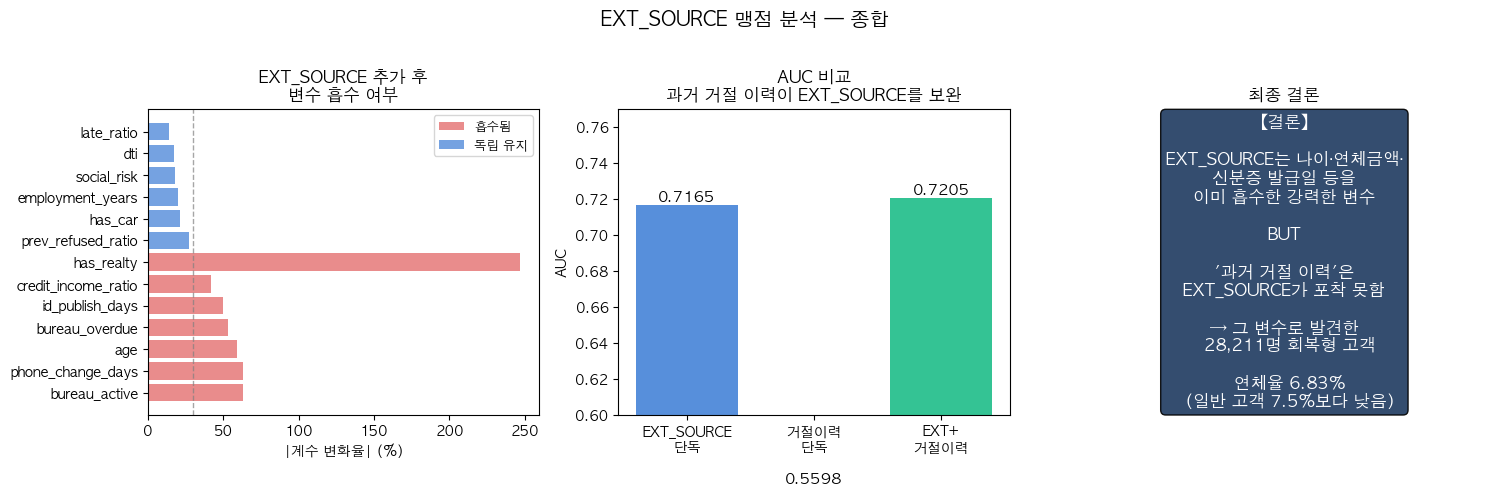


✅ 분석 완료
   EXT_SOURCE가 흡수한 변수: 7개
   독립적으로 유지된 변수: 6개
   EXT_SOURCE 맹점에서 발견한 타겟: 24,950명


In [14]:
# ── 최종 요약 시각화 ────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# (1) 흡수 vs 독립 변수 요약
absorbed_vars = change_df[change_df['흡수됨']]['변수'].tolist()
independent_vars = change_df[~change_df['흡수됨']]['변수'].tolist()
ax = axes[0]
ax.barh(absorbed_vars,
        [abs(change_df[change_df['변수']==v]['변화(%)'].values[0]) for v in absorbed_vars],
        color='#e05c5c', alpha=0.7, label='흡수됨')
ax.barh(independent_vars,
        [abs(change_df[change_df['변수']==v]['변화(%)'].values[0]) for v in independent_vars],
        color='#3a7bd5', alpha=0.7, label='독립 유지')
ax.axvline(30, color='gray', ls='--', lw=1, alpha=0.7)
ax.set_xlabel('|계수 변화율| (%)')
ax.set_title('EXT_SOURCE 추가 후\n변수 흡수 여부', fontweight='bold')
ax.legend(fontsize=9)

# (2) AUC 비교
ax = axes[1]
names = ['EXT_SOURCE\n단독', '거절이력\n단독', 'EXT+\n거절이력']
aucs  = [r[1] for r in auc_results]
bars  = ax.bar(names, aucs, color=['#3a7bd5','#f5a623','#10b981'], alpha=0.85)
for bar, v in zip(bars, aucs):
    ax.text(bar.get_x()+bar.get_width()/2, v+0.002, f'{v:.4f}',
            ha='center', fontweight='bold', fontsize=11)
ax.set_ylim(0.6, 0.77)
ax.set_ylabel('AUC')
ax.set_title('AUC 비교\n과거 거절 이력이 EXT_SOURCE를 보완', fontweight='bold')

# (3) 결론 요약 텍스트
ax = axes[2]
ax.axis('off')
summary = (
    "【결론】\n\n"
    "EXT_SOURCE는 나이·연체금액·\n"
    "신분증 발급일 등을\n"
    "이미 흡수한 강력한 변수\n\n"
    "BUT\n\n"
    "'과거 거절 이력'은\n"
    "EXT_SOURCE가 포착 못함\n\n"
    "→ 그 변수로 발견한\n"
    "  28,211명 회복형 고객\n\n"
    "  연체율 6.83%\n"
    "  (일반 고객 7.5%보다 낮음)"
)
ax.text(0.5, 0.5, summary, transform=ax.transAxes,
        fontsize=12, va='center', ha='center',
        bbox=dict(boxstyle='round', facecolor='#1E3A5F', alpha=0.9),
        color='white', fontweight='bold')
ax.set_title('최종 결론', fontweight='bold')
plt.suptitle('EXT_SOURCE 맹점 분석 — 종합', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout(); plt.show()

print('\n✅ 분석 완료')
print(f'   EXT_SOURCE가 흡수한 변수: {len(absorbed_vars)}개')
print(f'   독립적으로 유지된 변수: {len(independent_vars)}개')
print(f'   EXT_SOURCE 맹점에서 발견한 타겟: {len(target_group):,}명')